In [ ]:
import pickle
import warnings

from keras import metrics
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from keras.layers import Dense, Dropout
from keras.models import Sequential
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")


In [147]:
from bank_churn_predictions.config import MODELS_DIR
from bank_churn_predictions.dataset import load_smote_data, load_test_data


In [148]:
X_train_sm, y_train_sm = load_smote_data().drop(columns=["Exited"]), load_smote_data()["Exited"]
X_test, y_test = load_test_data().drop(columns=["Exited"]), load_test_data()["Exited"]

2026-10-09 18:16:26.021 | INFO     | bank_churn_predictions.dataset:load_smote_data:96 - Loading SMOTE dataset from D:\Ravindu\Programming\My Roadmap\Phase 1\bank_churn_predictions\data\processed\SMOTE.csv
2026-10-09 18:16:26.058 | INFO     | bank_churn_predictions.dataset:load_smote_data:100 - Loaded 11944 rows and 15 columns
2026-10-09 18:16:26.060 | INFO     | bank_churn_predictions.dataset:load_smote_data:96 - Loading SMOTE dataset from D:\Ravindu\Programming\My Roadmap\Phase 1\bank_churn_predictions\data\processed\SMOTE.csv
2026-10-09 18:16:26.094 | INFO     | bank_churn_predictions.dataset:load_smote_data:100 - Loaded 11944 rows and 15 columns
2026-10-09 18:16:26.095 | INFO     | bank_churn_predictions.dataset:load_test_data:76 - Loading test dataset from D:\Ravindu\Programming\My Roadmap\Phase 1\bank_churn_predictions\data\processed\test_data.csv
2026-10-09 18:16:26.108 | INFO     | bank_churn_predictions.dataset:load_test_data:80 - Loaded 2500 rows and 15 columns
2026-10-09 18:

## Defining Common Functions

In [149]:
def score_function(model, X_test, y_test):
    predicted_values = model.predict(X_test)
    report_df = pd.DataFrame(
        columns=[
            "Accuracy Score",
            "Precision",
            "Recall",
            "F1 Score",
            "Specificity",
            "Balanced Accuracy Score",
        ]
    )
    report_df.loc[0] = (
        accuracy_score(y_test, predicted_values),
        precision_score(y_test, predicted_values),
        recall_score(y_test, predicted_values),
        f1_score(y_test, predicted_values),
        recall_score(y_test, predicted_values, pos_label=0),
        balanced_accuracy_score(y_test, predicted_values),
    )
    return report_df


In [150]:
def displayConfusionMatrix(model, X_test, y_test):
    plt.figure(figsize=(10, 6))
    ConfusionMatrixDisplay(confusion_matrix(y_test, model.predict(X_test))).plot()
    print(confusion_matrix(y_test, model.predict(X_test)))
    plt.show()


## Hyperoptimizing Logistic Regression

In [160]:
logistic_regression_params = {
    "C": [0.001, 0.01, 0.1, 1, 10, 100, 1000],
    "penalty": ["l1", "l2"],
    "solver": ["liblinear", "saga"],
    "class_weight": [None, "balanced"],
    "max_iter": [100, 300, 500, 1000],
}

In [161]:
scoring = {
    "f1": "f1",
    "balanced_accuracy": "balanced_accuracy",
    "precision": "precision",
    "recall": "recall",
    "roc_auc": "roc_auc",
}

In [162]:
logistic_regression_search = RandomizedSearchCV(
    estimator=LogisticRegression(),
    scoring=scoring,
    param_distributions=logistic_regression_params,
    n_iter=20,
    cv=5,
    n_jobs=-1,
    refit="f1",
    random_state=49,
)

In [163]:
logistic_regression_search.fit(X_train_sm, y_train_sm)

,estimator,LogisticRegression()
,param_distributions,"{'C': [0.001, 0.01, ...], 'class_weight': [None, 'balanced'], 'max_iter': [100, 300, ...], 'penalty': ['l1', 'l2'], ...}"
,n_iter,20
,scoring,"{'balanced_accuracy': 'balanced_accuracy', 'f1': 'f1', 'precision': 'precision', 'recall': 'recall', ...}"
,n_jobs,-1
,refit,'f1'
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,49
,error_score,nan


In [164]:
logistic_regression_report = score_function(logistic_regression_search, X_test, y_test)

In [165]:
logistic_regression_report

,Accuracy Score,Precision,Recall,F1 Score,Specificity,Balanced Accuracy Score
0,0.7196,0.385167,0.632613,0.47881,0.741838,0.687226


<p>The model demonstrates an extremely low precision score, which would mean that this model faces particular issues when confidently predicting a positive case, with most of its 'positive predictions' being incorrect; it boasts an acceptable but still low recall score and a very low f1 score, necessitating investigation into further models</p>

## Hyperoptimizing Decision Trees 

In [166]:
dec_tree_params = {
    "max_depth": [5, 8, 12, None],
    "min_samples_split": [2, 4, 6],
    "max_features": [3, 6, 9, 12],
    "ccp_alpha": [0.001, 0.01, 0.1, 0],
}

In [167]:
dec_tree_scoring = {
    "f1": "f1",
    "balanced_accuracy": "balanced_accuracy",
    "recall": "recall",
    "roc_auc": "roc_auc",
}

In [168]:
dec_search = GridSearchCV(
    estimator=DecisionTreeClassifier(),
    scoring=dec_tree_scoring,
    param_grid=dec_tree_params,
    cv=3,
    n_jobs=-1,
    refit="balanced_accuracy",
)

In [169]:
dec_search.fit(X_train_sm, y_train_sm)

,estimator,DecisionTreeClassifier()
,param_grid,"{'ccp_alpha': [0.001, 0.01, ...], 'max_depth': [5, 8, ...], 'max_features': [3, 6, ...], 'min_samples_split': [2, 4, ...]}"
,scoring,"{'balanced_accuracy': 'balanced_accuracy', 'f1': 'f1', 'recall': 'recall', 'roc_auc': 'roc_auc'}"
,n_jobs,-1
,refit,'balanced_accuracy'
,cv,3
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'gini'


In [170]:
dec_tree_report = score_function(dec_search, X_test, y_test)
dec_tree_report

,Accuracy Score,Precision,Recall,F1 Score,Specificity,Balanced Accuracy Score
0,0.8,0.507488,0.599214,0.54955,0.851331,0.725273


[[1695  296]
 [ 204  305]]


<Figure size 1000x600 with 0 Axes>

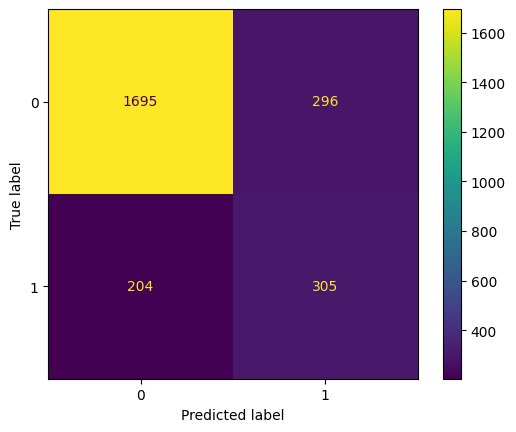

In [171]:
displayConfusionMatrix(dec_search, X_test, y_test)

<p>It has a significantly low acucracy score and balanced accuracy score, low recall and precision, indicating its inability to convincingly seperate positives classifications from negative ones, and vice versa.</p>

### Hyperoptimizing SVC 

In [172]:
SVC_params = {
    "C": [1, 2, 4, 6],
    "kernel": ["rbf", "poly", "sigmoid"],
    "degree": [3, 4, 6],
    "coef0": [1, 2, 3],
    "gamma": ["scale", "auto"],
}


In [173]:
SVC_scoring = {
    "f1": "f1",
    "balanced_accuracy": "balanced_accuracy",
    "recall": "recall",
    "roc_auc": "roc_auc",
}

In [174]:
"""svc_search = RandomizedSearchCV(
    SVC(class_weight='balanced'),
    param_distributions=SVC_params,
    n_iter=15,
    cv=3,
    scoring=SVC_scoring,
    refit="balanced_accuracy",
    n_jobs=-1,
)
svc_search.fit(X_train_sm, y_train_sm)"""

print(
    "I have commented the above code because running the randomized search estimator was highly computationally expensive and took a lot of time. Therefore, I instead ran it once and I dumped the model into a file that Iwill be directly importing here. If you want to test out the model hyperoptimizing for yourself, uncomment the above line and run it"
)

I have commented the above code because running the randomized search estimator was highly computationally expensive and took a lot of time. Therefore, I instead ran it once and I dumped the model into a file that Iwill be directly importing here. If you want to test out the model hyperoptimizing for yourself, uncomment the above line and run it


In [175]:
with open(MODELS_DIR / "svc-3.pkl", "rb") as file:
    svc_search = pickle.load(file)

In [176]:
score_function(svc_search, X_test, y_test)

,Accuracy Score,Precision,Recall,F1 Score,Specificity,Balanced Accuracy Score
0,0.7772,0.462025,0.573674,0.511832,0.829232,0.701453


In [177]:
svc_report = score_function(svc_search, X_test, y_test)
svc_report

,Accuracy Score,Precision,Recall,F1 Score,Specificity,Balanced Accuracy Score
0,0.7772,0.462025,0.573674,0.511832,0.829232,0.701453


<p>This model shows a marked improvement compared to its predecessors. It is more successfull at identifying the two types of classes and has a noticeably lower rate of false negatives and false positives </p>

## Hyperoptimizing Random Forest 

In [ ]:
random_forest_params = {
    "n_estimators": [200, 300],
    "max_depth": [5, 8, None],
    "min_samples_split": [2, 4, 6, 8],
    "min_samples_leaf": [1, 3, 5],
}

In [ ]:
scoring = {
    "f1": "f1",
    "balanced_accuracy": "balanced_accuracy",
    "precision": "precision",
    "recall": "recall",
    "roc_auc": "roc_auc",
}

In [ ]:
search = RandomizedSearchCV(
    estimator=RandomForestClassifier(class_weight="balanced"),
    scoring=scoring,
    param_distributions=random_forest_params,
    n_iter=20,
    cv=5,
    n_jobs=-1,
    refit="f1",
    random_state=49,
)

In [ ]:
search

,estimator,RandomForestC...ht='balanced')
,param_distributions,"{'max_depth': [5, 8, ...], 'min_samples_leaf': [1, 3, ...], 'min_samples_split': [2, 4, ...], 'n_estimators': [200, 300]}"
,n_iter,20
,scoring,"{'balanced_accuracy': 'balanced_accuracy', 'f1': 'f1', 'precision': 'precision', 'recall': 'recall', ...}"
,n_jobs,-1
,refit,'f1'
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,49
,error_score,nan


In [ ]:
# search.fit(X_train, y_train)
with open(MODELS_DIR / "random_forest.pkl", "rb") as f:
    search = pickle.load(f)
"""
for the purposes of performance, I have already trained the model and dumped it into a pkl file, which is what Iare using here, using the exact same parameters as the commented line of code
this was done as hyperoptimizing is computationally expensive. if you want to test it by yourself, feel free to uncomment the above code and run it
"""

'\nfor the purposes of performance, I have already trained the model and dumped it into a pkl file, which is what Iare using here, using the exact same parameters as the commented line of code\nthis was done as hyperoptimizing is computationally expensive. if you want to test it by yourself, feel free to uncomment the above code and run it\n'

In [ ]:
random_forest_report = score_function(search, X_test, y_test)
random_forest_report

,Accuracy Score,Precision,Recall,F1 Score,Specificity,Balanced Accuracy Score
0,0.8412,0.609375,0.612967,0.611166,0.899548,0.756257


In [ ]:
def score_function_without_model(predicted_values, y_pred):
    report_df = pd.DataFrame(
        columns=[
            "Accuracy Score",
            "Precision",
            "Recall",
            "F1 Score",
            "Specificity",
            "Balanced Accuracy Score",
        ]
    )
    report_df.loc[0] = (
        accuracy_score(y_pred, predicted_values),
        precision_score(y_pred, predicted_values),
        recall_score(y_pred, predicted_values),
        f1_score(y_pred, predicted_values),
        recall_score(y_pred, predicted_values, pos_label=0),
        balanced_accuracy_score(y_pred, predicted_values),
    )
    return report_df

In [ ]:
threshold_report_rf = pd.DataFrame(
    columns=[
        "Threshold",
        "Accuracy Score",
        "Precision",
        "Recall",
        "F1 Score",
        "Specificity",
        "Balanced Accuracy Score",
    ]
)
for index, threshold in enumerate(np.linspace(0, 1, 15)):
    pred = search.predict_proba(X_test.astype(float))
    pred = (pred[:, 1] >= threshold).astype(int)
    temp_report = score_function_without_model(pred, y_test)
    temp_report.insert(0, "Threshold", threshold)
    threshold_report_rf = pd.concat([threshold_report_rf, temp_report], axis=0)
threshold_report_rf

,Threshold,Accuracy Score,Precision,Recall,F1 Score,Specificity,Balanced Accuracy Score
0,0.000000,0.2036,0.203600,1.000000,0.338318,0.000000,0.500000
0,0.071429,0.3748,0.242172,0.972495,0.387779,0.221999,0.597247
0,0.142857,0.5224,0.291031,0.937132,0.444134,0.416374,0.676753
0,0.214286,0.6460,0.352433,0.882122,0.503646,0.585635,0.733879
0,0.285714,0.7248,0.410589,0.807466,0.544371,0.703666,0.755566
0,0.357143,0.7744,0.465923,0.738703,0.571429,0.783526,0.761115
0,0.428571,0.8176,0.540958,0.687623,0.605536,0.850829,0.769226
0,0.500000,0.8412,0.609375,0.612967,0.611166,0.899548,0.756257
0,0.571429,0.8524,0.669082,0.544204,0.600217,0.931190,0.737697
0,0.642857,0.8572,0.726190,0.479371,0.577515,0.953792,0.716582


[[1791  200]
 [ 197  312]]


<Figure size 1000x600 with 0 Axes>

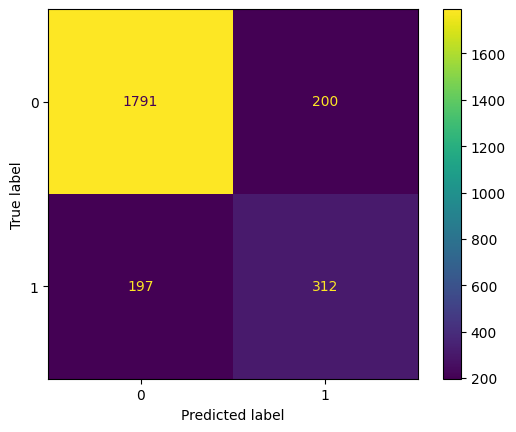

In [ ]:
displayConfusionMatrix(search, X_test, y_test)

<p>The balanced accuracy score for the regression tree is below average; the lower preicsion and recall demonstrate that the model is not sufficiently capable of diagnosing ture positives from true negatives. Investigation into the use of differring thresholds did not offer any additional insights, as its apparent that the threshold selected by the model internally is already close to the most ooptimum threshold across alls scores. It does display a promising specificity score, but the overall scores across the board clearly show that other models require investigation.</p>

## Hyperoptimizing K Nearest Neighbors

In [178]:
KNN_Params = {
    "n_neighbors": [3, 5, 8, 10],
    "weights": ["uniform", "distance"],
    "leaf_size": [30, 40, 50],
    "p": [2, 4, 6],
}

In [179]:
KNN_Scoring = {
    "f1": "f1",
    "balanced_accuracy": "balanced_accuracy",
    "recall": "recall",
    "roc_auc": "roc_auc",
}

In [180]:
knn_search = GridSearchCV(
    estimator=KNeighborsClassifier(),
    scoring=KNN_Scoring,
    param_grid=KNN_Params,
    cv=3,
    n_jobs=-1,
    refit="balanced_accuracy",
)

In [ ]:
# knn_search.fit(X_train_sm, y_train_sm)

In [182]:
with open(MODELS_DIR / "knn.pkl", "rb") as file:
    knn_search = pickle.load(file)

In [183]:
knn_report = score_function(knn_search, X_test, y_test)
knn_report

,Accuracy Score,Precision,Recall,F1 Score,Specificity,Balanced Accuracy Score
0,0.728,0.376266,0.510806,0.433333,0.783526,0.647166


In [184]:
overall_report = pd.concat(
    (logistic_regression_report, svc_report, random_forest_report, dec_tree_report, knn_report),
    axis=0,
)
overall_report.insert(
    0, "type", ["logistic_regression", "svc", "random forest", "dec_tree", "knn"]
)
overall_report

,type,Accuracy Score,Precision,Recall,F1 Score,Specificity,Balanced Accuracy Score
0,logistic_regression,0.7196,0.385167,0.632613,0.478810,0.741838,0.687226
0,svc,0.7772,0.462025,0.573674,0.511832,0.829232,0.701453
0,random forest,0.8412,0.609375,0.612967,0.611166,0.899548,0.756257
0,dec_tree,0.8000,0.507488,0.599214,0.549550,0.851331,0.725273
0,knn,0.7280,0.376266,0.510806,0.433333,0.783526,0.647166


<p>
    Use of K Nearest Neighbors here did not yield any useful results. It demonstrated poor precision and recall, demonstrating that out of all the positive predictions the model made for a specific value, it had a high rate of failure and predicted many false positives; the low recall also means that the model is exceptionally bad at identifying all the real positive cases in the testing set. It does demonstrate a strong specificity, but this is common across all models which makes it not worth commenting upon. It also has a significantly poor balanced accuracy score, which indicates that the model is not fit for use in predictions 
</p>

<p>Overall, SVC shows the strongest lead in specificity, accuracy, balanaced accuracy score and recall compared to other models. Yet its notable that its precision and f1 score is relatively low.Therefore I will look into the application of neural networks for this problem</p>

## Hyperoptimizing XGB 

In [185]:
XGB_Params = {
    "n_estimators": [100, 200, 400],
    "learning_rate": [0.1, 0.3, 0.5, 0.7],
    "max_depth": [4, 6, 8, 10],
    "subsample": [0.5, 1],
    "colsample_bytree": [0.5, 0.75, 1],
    "gamma": [0, 0.5, 1],
    "reg_lambda": [1, 2, 3],
}

In [186]:
xgb_search = RandomizedSearchCV(
    estimator=XGBClassifier(),
    scoring="balanced_accuracy",
    param_distributions=XGB_Params,
    cv=3,
    n_jobs=-1,
    error_score="raise",
)

In [187]:
# xgb_search.fit(X_train_sm, y_train_sm)
# commented this out since its computationally costly to run, I dumped the model resulting from this into a pkl file

In [ ]:
with open(MODELS_DIR / "xgbclassifier-2.pkl", "rb") as f:
    xgbclassifier = pickle.load(f)

In [189]:
xgboost_report = score_function(xgbclassifier, X_test.astype(float), y_test)
xgboost_report

,Accuracy Score,Precision,Recall,F1 Score,Specificity,Balanced Accuracy Score
0,0.8364,0.589928,0.644401,0.615962,0.885485,0.764943


In [190]:
overall_report = pd.concat(
    (svc_report, random_forest_report, dec_tree_report, knn_report, xgboost_report), axis=0
)
overall_report.insert(0, "type", ["svc", "random forest", "dec_tree", "knn", "xgboost"])
overall_report

,type,Accuracy Score,Precision,Recall,F1 Score,Specificity,Balanced Accuracy Score
0,svc,0.7772,0.462025,0.573674,0.511832,0.829232,0.701453
0,random forest,0.8412,0.609375,0.612967,0.611166,0.899548,0.756257
0,dec_tree,0.8000,0.507488,0.599214,0.549550,0.851331,0.725273
0,knn,0.7280,0.376266,0.510806,0.433333,0.783526,0.647166
0,xgboost,0.8364,0.589928,0.644401,0.615962,0.885485,0.764943


<p>This model has more promising results. While it does suffer for relatively low recall and precision, its worth noting that both of these values are on par with or slightly excel the same metrics for the other models looked at thus far. Its f1 score is also for the most part equal to the f1 scores demonstrated for the other models derived thus far and its balanced accuracy score is the highest amongst the current computed models. This makes xgboost a model to be considered as a strong contender for churn predictions </p>

## Neural Networks

In [191]:
initial_nn_classifier = Sequential()
initial_nn_classifier.add(Dense(units=100, activation="relu", input_dim=X_train_sm.shape[1]))
initial_nn_classifier.add(Dense(units=50, activation="relu"))
initial_nn_classifier.add(Dense(units=20, activation="relu"))
initial_nn_classifier.add(Dropout(0.2))
initial_nn_classifier.add(Dense(units=1, activation="sigmoid"))

initial_nn_classifier.compile(optimizer="adam", loss="binary_crossentropy")

initial_nn_classifier.fit(
    X_train_sm.astype(float), y_train_sm, batch_size=40, epochs=60, validation_split=0.2, verbose=0
)

In [192]:
pred = initial_nn_classifier.predict(X_test.astype(float))
pred = (pred >= 0.5).astype(int)
inital_nn_report = score_function_without_model(pred, y_test)
inital_nn_report

79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


,Accuracy Score,Precision,Recall,F1 Score,Specificity,Balanced Accuracy Score
0,0.8176,0.55332,0.540275,0.54672,0.888498,0.714387


<p>These are some good initial results, but its worth further modifying the NN to see its performance after more layers and parameters are added</p>

In [193]:
classifier = Sequential()

classifier.add(
    Dense(units=64, kernel_initializer="uniform", activation="relu", input_dim=X_train_sm.shape[1])
)

classifier.add(Dense(units=32, kernel_initializer="uniform", activation="relu"))

classifier.add(Dropout(0.2))

classifier.add(Dense(units=16, kernel_initializer="uniform", activation="relu"))

classifier.add(Dropout(0.2))

classifier.add(Dense(units=16, kernel_initializer="uniform", activation="relu"))

classifier.add(Dense(units=1, kernel_initializer="uniform", activation="sigmoid"))

reduce_lr = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6)

early_stopping = EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)

In [194]:
classifier.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        metrics.Precision(name="precision"),
        metrics.Recall(name="recall"),
    ],
)
classifier.fit(
    X_train_sm.astype(float),
    y_train_sm,
    batch_size=32,
    epochs=100,
    validation_split=0.2,
    callbacks=[early_stopping, reduce_lr],
    verbose=0,
)

In [195]:
threshold_report_nn = pd.DataFrame(
    columns=[
        "Threshold",
        "Accuracy Score",
        "Precision",
        "Recall",
        "F1 Score",
        "Specificity",
        "Balanced Accuracy Score",
    ]
)
for index, threshold in enumerate(np.linspace(0, 1, 15)):
    pred = classifier.predict(X_test.astype(float))
    pred = (pred >= threshold).astype(int)
    temp_report = score_function_without_model(pred, y_test)
    temp_report.insert(0, "Threshold", threshold)
    threshold_report_nn = pd.concat([threshold_report_nn, temp_report])

79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step  
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 941us/step
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 986us/step
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 829us/step
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 953us/step
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 861us/step
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  


In [196]:
threshold_report_nn

,Threshold,Accuracy Score,Precision,Recall,F1 Score,Specificity,Balanced Accuracy Score
0,0.000000,0.2036,0.203600,1.000000,0.338318,0.000000,0.500000
0,0.071429,0.3884,0.244233,0.956778,0.389133,0.243094,0.599936
0,0.142857,0.5544,0.301899,0.905697,0.452849,0.464591,0.685144
0,0.214286,0.6516,0.351639,0.842829,0.496241,0.602712,0.722771
0,0.285714,0.7136,0.397626,0.789784,0.528947,0.694124,0.741954
0,0.357143,0.7520,0.434629,0.724951,0.543446,0.758915,0.741933
0,0.428571,0.7868,0.483516,0.691552,0.569119,0.811150,0.751351
0,0.500000,0.8144,0.537438,0.634578,0.581982,0.860372,0.747475
0,0.571429,0.8344,0.596741,0.575639,0.586000,0.900552,0.738095
0,0.642857,0.8448,0.647202,0.522593,0.578261,0.927172,0.724883


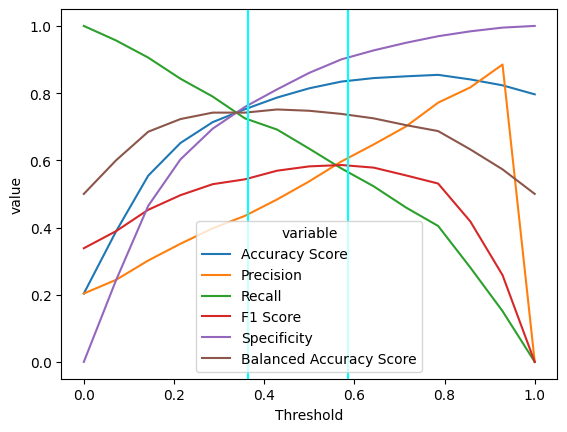

In [197]:
modified_threshold = pd.melt(threshold_report_nn, ["Threshold"])

sns.lineplot(data=modified_threshold, x="Threshold", y="value", hue="variable")
plt.axvline(0.364, color="aqua")
plt.axvline(0.585, color="aqua")

<p>The above graph displays how the metrics vary across thresholds. When choosing the threshold, I have to consider the tradeoff between recall and precision, thereby giving us two thresholds to choose from, as illustrated in the graph, namely 0.364 and 0.585. It can be clearly seen that specificity, f1 score and accuracy are all higher at 0.585 than 0.364, leading us to choose 0.585 as the threshold for the neural network</p>

<p>
    Two dropout layers were used to prevent overfitting. There were two primary callbacks used to monitor neural network performance, the first being the use of Early Stopping to prevent the model from wasting computational power computing epochs if there isnt any significant improvement between epochs in terms of validation loss. Furthermore ReduceLRonPlateau was used to drop the learning rate if val_loss increased to prevent the model from overshooting and to get it to make incremental changes to reach the optimal solution.
</p>
<p>
    After training was completed, I computed and measured its performance across a set of different thresholds to identify which threshold would give the best model performance. There were two potential thresholds I considered, each of which would either maximise recall or precision; Iultimately went for the threshold that would maximise precision, as that threshold reports better parameters compared to the other threshold
</p>
<p>The neural network did not offer any significant improvements across computed metrics compared to the models created thus far yet its performance is quite comparable to the current top performing models of xgboost and random forest, making it worth considering.</p>

79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


,Accuracy Score,Precision,Recall,F1 Score,Specificity,Balanced Accuracy Score
0,0.8372,0.609442,0.557957,0.582564,0.908589,0.733273


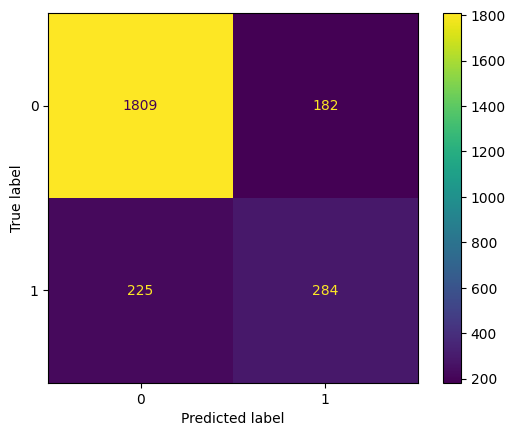

In [198]:
pred = classifier.predict(X_test.astype(float))
pred = (pred >= 0.585).astype(int).flatten()

ConfusionMatrixDisplay(confusion_matrix(y_test, pred)).plot()
score_function_without_model(pred, y_test)

In [199]:
overall_report = pd.concat(
    (
        logistic_regression_report,
        svc_report,
        random_forest_report,
        dec_tree_report,
        knn_report,
        xgboost_report,
        score_function_without_model(pred, y_test),
    ),
    axis=0,
)
overall_report.insert(
    0,
    "type",
    [
        "logistic_regression",
        "svc",
        "random forest",
        "dec_tree",
        "knn",
        "xgboost",
        "neural network",
    ],
)
overall_report

,type,Accuracy Score,Precision,Recall,F1 Score,Specificity,Balanced Accuracy Score
0,logistic_regression,0.7196,0.385167,0.632613,0.478810,0.741838,0.687226
0,svc,0.7772,0.462025,0.573674,0.511832,0.829232,0.701453
0,random forest,0.8412,0.609375,0.612967,0.611166,0.899548,0.756257
0,dec_tree,0.8000,0.507488,0.599214,0.549550,0.851331,0.725273
0,knn,0.7280,0.376266,0.510806,0.433333,0.783526,0.647166
0,xgboost,0.8364,0.589928,0.644401,0.615962,0.885485,0.764943
0,neural network,0.8372,0.609442,0.557957,0.582564,0.908589,0.733273


<Axes: xlabel='type', ylabel='value'>

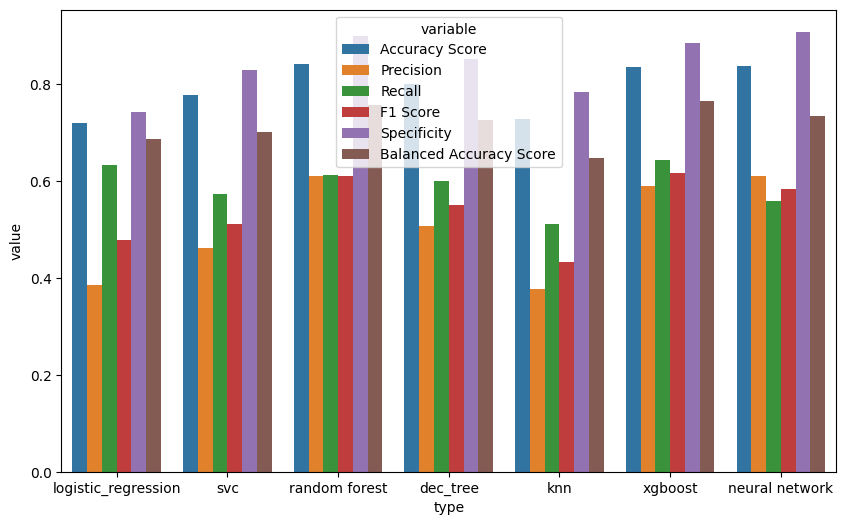

In [200]:
df_long = pd.melt(overall_report, ["type"])
plt.figure(figsize=(10, 6))
sns.barplot(data=df_long, x="type", y="value", hue="variable")

In [201]:
overall_report.sort_values(
    by=[
        "Accuracy Score",
        "Precision",
        "Recall",
        "F1 Score",
        "Specificity",
        "Balanced Accuracy Score",
    ],
    ascending=False,
)

,type,Accuracy Score,Precision,Recall,F1 Score,Specificity,Balanced Accuracy Score
0,random forest,0.8412,0.609375,0.612967,0.611166,0.899548,0.756257
0,neural network,0.8372,0.609442,0.557957,0.582564,0.908589,0.733273
0,xgboost,0.8364,0.589928,0.644401,0.615962,0.885485,0.764943
0,dec_tree,0.8000,0.507488,0.599214,0.549550,0.851331,0.725273
0,svc,0.7772,0.462025,0.573674,0.511832,0.829232,0.701453
0,knn,0.7280,0.376266,0.510806,0.433333,0.783526,0.647166
0,logistic_regression,0.7196,0.385167,0.632613,0.478810,0.741838,0.687226


<p>Overall the top 3 models are random forest, xgboost and the neural network</p>